In [1]:

import sys
import pandas as pd
import yfinance as yf
import plotly.express as px
import streamlit as st

print("Python berhasil dijalankan!")
print("Lokasi Python:", sys.executable)
print("Yahoo Finance:", yf.__version__)
print("Pandas:", pd.__version__)
print("Streamlit:", st.__version__)

ImportError: Unable to import required dependency numpy. Please see the traceback for details.

In [1]:
import sys
import numpy as np
import pandas as pd
import yfinance as yf
import plotly.express as px
import streamlit as st

print("Python berhasil dijalankan!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Yahoo Finance:", yf.__version__)
print("Streamlit:", st.__version__)

Python berhasil dijalankan!
NumPy: 2.2.6
Pandas: 2.3.3
Yahoo Finance: 1.8.0
Streamlit: 1.67.0


In [2]:

import yfinance as yf
import pandas as pd

# Mengambil data saham BBCA
saham = yf.Ticker("BBCA.JK")

# Mengambil riwayat harga 1 tahun
data = saham.history(period="1y")

# Menampilkan 5 data terbaru
data.tail()


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-11-10 00:00:00+07:00,5325.0,5400.0,5275.0,5300.0,112221300,0.0,0.0
2026-11-11 00:00:00+07:00,5350.0,5350.0,5250.0,5325.0,92364800,0.0,0.0
2026-11-12 00:00:00+07:00,5325.0,5475.0,5275.0,5475.0,192936300,0.0,0.0
2026-11-13 00:00:00+07:00,5475.0,5650.0,5425.0,5500.0,218808600,0.0,0.0
2026-11-16 00:00:00+07:00,5500.0,5525.0,5425.0,5475.0,74752000,0.0,0.0


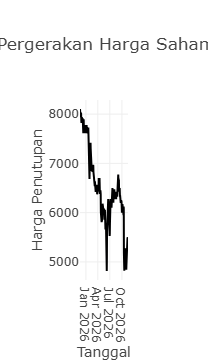

In [3]:

import plotly.express as px

# Membuat grafik harga penutupan saham
grafik = px.line(
    data,
    x=data.index,
    y="Close",
    title="Grafik Pergerakan Harga Saham BBCA",
    labels={
        "Date": "Tanggal",
        "Close": "Harga Penutupan"
    }
)

grafik.show()


In [4]:

%%writefile app.py

import streamlit as st
import yfinance as yf
import plotly.express as px

st.set_page_config(
    page_title="Yahoo Finance Dashboard",
    page_icon="📈",
    layout="wide"
)

st.title("📈 Yahoo Finance Dashboard")
st.write("Aplikasi pemantauan harga saham menggunakan Yahoo Finance.")

# Pilihan saham
daftar_saham = {
    "BBCA - Bank Central Asia": "BBCA.JK",
    "BBRI - Bank Rakyat Indonesia": "BBRI.JK",
    "BMRI - Bank Mandiri": "BMRI.JK",
    "TLKM - Telkom Indonesia": "TLKM.JK",
    "ASII - Astra International": "ASII.JK",
    "AAPL - Apple Inc": "AAPL"
}

pilihan = st.sidebar.selectbox(
    "Pilih Saham",
    list(daftar_saham.keys())
)

ticker = daftar_saham[pilihan]

periode = st.sidebar.selectbox(
    "Pilih Periode",
    ["1mo", "3mo", "6mo", "1y", "2y", "5y"]
)

if st.sidebar.button("Tampilkan Data"):
    st.cache_data.clear()

try:
    saham = yf.Ticker(ticker)
    data = saham.history(period=periode)

    if data.empty:
        st.error("Data saham tidak tersedia.")
    else:
        harga_terakhir = data["Close"].iloc[-1]
        harga_sebelumnya = data["Close"].iloc[-2] if len(data) > 1 else harga_terakhir
        perubahan = harga_terakhir - harga_sebelumnya

        col1, col2, col3 = st.columns(3)

        col1.metric(
            "Harga Terakhir",
            f"{harga_terakhir:,.2f}"
        )

        col2.metric(
            "Perubahan Harga",
            f"{perubahan:,.2f}"
        )

        col3.metric(
            "Volume Terakhir",
            f"{data['Volume'].iloc[-1]:,.0f}"
        )

        st.subheader("Grafik Pergerakan Harga Saham")

        grafik = px.line(
            data,
            x=data.index,
            y="Close",
            title=f"Pergerakan Harga {ticker}",
            labels={
                "Date": "Tanggal",
                "Close": "Harga Penutupan"
            }
        )

        st.plotly_chart(grafik, use_container_width=True)

        st.subheader("Data Historis Saham")
        st.dataframe(data, use_container_width=True)

except Exception as e:
    st.error(f"Terjadi kesalahan: {e}")


Writing app.py


In [5]:

%%writefile requirements.txt

streamlit
yfinance
pandas
numpy
plotly


Writing requirements.txt
